# RetailPulse 2.0 – E-commerce Sales & Customer Intelligence Analysis

**Project Type:** Data Analytics

**Tools Used:** Python, Pandas, NumPy, Matplotlib, Google Colab

**Dataset:** UCI Online Retail Dataset

**Objective:** To analyse e-commerce sales transactions, identify product performance, understand customer purchasing behaviour and segment customers using RFM analysis.

## 1. Dataset Understanding

The Online Retail dataset contains transactional records from a UK-based online retail business covering the period December 2010 to December 2011.

The dataset was provided in a ZIP file containing an Excel workbook. The file was uploaded to Google Colab, extracted and loaded for analysis.

It contains information about invoices, products, quantities, prices, invoice dates, customers and countries.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Online Retail Transactions.zip to Online Retail Transactions (1).zip


In [ ]:
import os
import glob

zip_files = glob.glob("*.zip")

zip_files

['Online Retail Transactions.zip', 'Online Retail Transactions (1).zip']

In [ ]:
import zipfile

with zipfile.ZipFile(zip_files[0], 'r') as zip_ref:
    zip_ref.extractall("RetailPulse_Data")

In [ ]:
os.listdir("RetailPulse_Data")

['Online Retail.xlsx']

In [ ]:
import pandas as pd

df = pd.read_excel("RetailPulse_Data/Online Retail.xlsx")

## 2. Exploratory Data Analysis (EDA)

In this section, the dataset is explored to understand its structure, dimensions, column names, data types and missing values before performing data cleaning and analysis.

In [ ]:
df.shape

(541909, 8)

In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [ ]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [ ]:
df[df['CustomerID'].isnull()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom


In [ ]:
missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

print(missing_percentage)

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64


## 3. Data Cleaning & Preparation

In this section, the dataset is cleaned and prepared for analysis by identifying and handling duplicate records, missing values and invalid transaction values.

The original dataset is preserved during the cleaning process, and relevant records are retained for further analysis.

In [ ]:
df.duplicated().sum()

np.int64(5268)

In [ ]:
df[df.duplicated()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [ ]:
df[df.duplicated(keep=False)].sort_values(
    by=['InvoiceNo', 'StockCode']
).head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [ ]:
duplicate_rows = df[df.duplicated(keep=False)]

exact_duplicates = duplicate_rows.drop_duplicates()

print("Total duplicate rows:", len(duplicate_rows))
print("Unique duplicate records:", len(exact_duplicates))

Total duplicate rows: 10147
Unique duplicate records: 4879


In [ ]:
df.duplicated().sum()

np.int64(5268)

In [ ]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (536641, 8)
Remaining duplicate rows: 0


In [ ]:
df[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,536641.000000,536641.000000
mean,9.620029,4.632656
std,219.130156,97.233118
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [ ]:
print("Negative Quantity:", (df['Quantity'] < 0).sum())

print("Negative UnitPrice:", (df['UnitPrice'] < 0).sum())

Negative Quantity: 10587
Negative UnitPrice: 2


In [ ]:
df[df['UnitPrice'] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [ ]:
df = df[df['UnitPrice'] >= 0]

print("Dataset shape:", df.shape)
print("Negative UnitPrice records:", (df['UnitPrice'] < 0).sum())

Dataset shape: (536639, 8)
Negative UnitPrice records: 0


In [ ]:
df[df['Quantity'] < 0]['InvoiceNo'].astype(str).str.startswith('C').sum()

np.int64(9251)

In [ ]:
df[(df['Quantity'] < 0) &
   (~df['InvoiceNo'].astype(str).str.startswith('C'))].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [ ]:
remaining_negative = df[
    (df['Quantity'] < 0) &
    (~df['InvoiceNo'].astype(str).str.startswith('C'))
]

print("Remaining records:", len(remaining_negative))

print(remaining_negative['Description'].value_counts(dropna=False))

print(remaining_negative['InvoiceNo'].head(20).tolist())

Remaining records: 1336
Description
NaN                862
check              120
damages             45
damaged             42
?                   41
                  ... 
lost??               1
wet                  1
wet boxes            1
????damages????      1
lost                 1
Name: count, Length: 139, dtype: int64
[536589, 536764, 536996, 536997, 536998, 537000, 537001, 537003, 537004, 537005, 537006, 537007, 537008, 537009, 537010, 537011, 537012, 537013, 537014, 537015]


In [ ]:
remaining_negative['InvoiceNo'].astype(str).str[0].value_counts()

,count
InvoiceNo,
5,1336


In [ ]:
print("Zero Quantity:", (df['Quantity'] == 0).sum())

Zero Quantity: 0


In [ ]:
print("Zero UnitPrice:", (df['UnitPrice'] == 0).sum())

print("Negative UnitPrice:", (df['UnitPrice'] < 0).sum())

Zero UnitPrice: 2510
Negative UnitPrice: 0


In [ ]:
df[df['UnitPrice'] == 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [ ]:
zero_price = df[df['UnitPrice'] == 0]

print("Total zero-price records:", len(zero_price))

print(zero_price['Description'].value_counts().head(15))

Total zero-price records: 2510
Description
check                            159
?                                 47
damages                           45
damaged                           43
found                             25
sold as set on dotcom             20
adjustment                        16
Damaged                           14
Unsaleable, destroyed.             9
FRENCH BLUE METAL DOOR SIGN 1      9
thrown away                        9
amazon                             8
FRENCH BLUE METAL DOOR SIGN 8      8
Found                              8
FRENCH BLUE METAL DOOR SIGN 3      7
Name: count, dtype: int64


In [ ]:
zero_price[zero_price['CustomerID'].notnull()].head(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom


In [ ]:
print("Zero-price records with CustomerID:",
      zero_price['CustomerID'].notnull().sum())

print("Zero-price records without CustomerID:",
      zero_price['CustomerID'].isnull().sum())

Zero-price records with CustomerID: 40
Zero-price records without CustomerID: 2470


In [ ]:
print("Missing CustomerID:", df['CustomerID'].isnull().sum())

print("Valid CustomerID:", df['CustomerID'].notnull().sum())

Missing CustomerID: 135035
Valid CustomerID: 401604


In [ ]:
print("Missing Description:", df['Description'].isnull().sum())

print("Valid Description:", df['Description'].notnull().sum())

Missing Description: 1454
Valid Description: 535185


In [ ]:
df[df['Description'].isnull()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [ ]:
df[df['Description'].isnull()]['StockCode'].nunique()

960

In [ ]:
missing_stockcodes = df[df['Description'].isnull()]['StockCode'].unique()

available_stockcodes = df[df['Description'].notnull()]['StockCode'].unique()

matching_stockcodes = set(missing_stockcodes) & set(available_stockcodes)

print("StockCodes with descriptions available elsewhere:", len(matching_stockcodes))

StockCodes with descriptions available elsewhere: 848


In [ ]:
description_mapping = df.dropna(subset=['Description']).drop_duplicates(
    subset=['StockCode']
).set_index('StockCode')['Description']

df['Description'] = df['Description'].fillna(
    df['StockCode'].map(description_mapping)
)

print("Remaining missing descriptions:", df['Description'].isnull().sum())

Remaining missing descriptions: 112


In [ ]:
df[df['Description'].isnull()].head(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
7187,536995,35951,NaN,57,2010-12-03 15:29:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
19628,537875,20849,NaN,1,2010-12-08 18:08:00,0.0,NaN,United Kingdom
19631,537878,72803B,NaN,1,2010-12-08 18:09:00,0.0,NaN,United Kingdom
21782,538133,85018C,NaN,3,2010-12-09 15:56:00,0.0,NaN,United Kingdom


In [ ]:
print("First transaction:", df['InvoiceDate'].min())

print("Last transaction:", df['InvoiceDate'].max())

First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00


In [ ]:
df['Country'].value_counts().head(15)

,count
Country,
United Kingdom,490298
Germany,9480
France,8541
EIRE,8184
Spain,2528
Netherlands,2371
Belgium,2069
Switzerland,1994
Portugal,1510


In [ ]:
print("Total countries:", df['Country'].nunique())

Total countries: 38


In [ ]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (536639, 8)

Missing Values:
InvoiceNo           0
StockCode           0
Description       112
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135035
Country             0
dtype: int64


## 4. Sales Performance Analysis

In this section, sales performance is analysed using transaction data. Key metrics such as Gross Sales, Returns and Net Sales are calculated, followed by monthly sales trends and country-wise sales analysis.

In [ ]:
df['Sales'] = df['Quantity'] * df['UnitPrice']

df[['Quantity', 'UnitPrice', 'Sales']].head(10)

,Quantity,UnitPrice,Sales
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34
5,2,7.65,15.30
6,6,4.25,25.50
7,6,1.85,11.10
8,6,1.85,11.10
9,32,1.69,54.08


In [ ]:
df['Sales'].sum()

np.float64(9748131.074000001)

In [ ]:
df[df['Quantity'] > 0]['Sales'].sum()

np.float64(10642110.804000001)

In [ ]:
df[df['Quantity'] < 0]['Sales'].sum()

np.float64(-893979.73)

In [ ]:
df[['Quantity', 'UnitPrice', 'Sales']].describe()

,Quantity,UnitPrice,Sales
count,536639.000000,536639.000000,536639.000000
mean,9.620061,4.673900,18.165156
std,219.130564,94.857114,380.055489
min,-80995.000000,0.000000,-168469.600000
25%,1.000000,1.250000,3.750000
50%,3.000000,2.080000,9.870000
75%,10.000000,4.130000,17.400000
max,80995.000000,38970.000000,168469.600000


In [ ]:
df.shape

(536639, 9)

In [ ]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,112
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135035
Country,0
Sales,0


In [ ]:
df['InvoiceNo'].astype(str).str.startswith('C').sum()

np.int64(9251)

In [ ]:
df[df['InvoiceNo'].astype(str).str.startswith('C')][['InvoiceNo', 'Quantity', 'UnitPrice', 'Sales']].head(10)

,InvoiceNo,Quantity,UnitPrice,Sales
141,C536379,-1,27.50,-27.50
154,C536383,-1,4.65,-4.65
235,C536391,-12,1.65,-19.80
236,C536391,-24,0.29,-6.96
237,C536391,-24,0.29,-6.96
238,C536391,-24,0.29,-6.96
239,C536391,-12,3.45,-41.40
240,C536391,-12,1.65,-19.80
241,C536391,-24,1.65,-39.60
939,C536506,-6,4.25,-25.50


In [ ]:
df[df['InvoiceNo'].astype(str).str.startswith('C')]['InvoiceNo'].nunique()

3836

In [ ]:
df[~df['InvoiceNo'].astype(str).str.startswith('C')].shape

(527388, 9)

In [ ]:
df[(~df['InvoiceNo'].astype(str).str.startswith('C')) & (df['Quantity'] < 0)].shape

(1336, 9)

In [ ]:
df[(~df['InvoiceNo'].astype(str).str.startswith('C')) & (df['Quantity'] < 0)][['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice', 'Sales']].head(15)


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Sales
2406,536589,21777,RECIPE BOX WITH METAL HEART,-10,0.0,-0.0
4347,536764,84952C,MIRROR LOVE BIRD T-LIGHT HOLDER,-38,0.0,-0.0
7188,536996,22712,CARD DOLLY GIRL,-20,0.0,-0.0
7189,536997,22028,PENNY FARTHING BIRTHDAY CARD,-20,0.0,-0.0
7190,536998,85067,CREAM SWEETHEART WALL CABINET,-6,0.0,-0.0
7192,537000,21414,SCALLOP SHELL SOAP DISH,-22,0.0,-0.0
7193,537001,21653,NaN,-6,0.0,-0.0
7195,537003,85126,LARGE ROUND CUTGLASS CANDLESTICK,-2,0.0,-0.0
7196,537004,21814,HEART T-LIGHT HOLDER,-30,0.0,-0.0
7197,537005,21692,SILVER LATTICE VANILLA CANDLE POT,-70,0.0,-0.0


In [ ]:
df[(~df['InvoiceNo'].astype(str).str.startswith('C')) & (df['Quantity'] < 0) & (df['UnitPrice'] == 0)].shape

(1336, 9)

In [ ]:
df[(df['Quantity'] > 0) & (df['UnitPrice'] == 0)].shape

(1174, 9)

In [ ]:
df[(df['Quantity'] > 0) & (df['UnitPrice'] == 0)]['CustomerID'].notna().sum()

np.int64(40)

In [ ]:
df[(df['Quantity'] > 0) & (df['UnitPrice'] == 0) & (df['CustomerID'].notna())][['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'CustomerID', 'Country']]

,InvoiceNo,StockCode,Description,Quantity,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,14410.0,United Kingdom


In [ ]:
df['InvoiceNo'].nunique()

25898

In [ ]:
df['CustomerID'].nunique()

4372

In [ ]:
df['CustomerID'].notna().sum()

np.int64(401604)

In [ ]:
customer_df = df.dropna(subset=['CustomerID']).copy()

customer_df.shape

(401604, 9)

In [ ]:
customer_df['CustomerID'].nunique()

4372

In [ ]:
customer_df.dtypes

,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object
Sales,float64


In [ ]:
customer_df['CustomerID'] = customer_df['CustomerID'].astype(int)

customer_df['CustomerID'].dtype

dtype('int64')

In [ ]:
customer_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 401604 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    401604 non-null  object        
 1   StockCode    401604 non-null  object        
 2   Description  401604 non-null  object        
 3   Quantity     401604 non-null  int64         
 4   InvoiceDate  401604 non-null  datetime64[ns]
 5   UnitPrice    401604 non-null  float64       
 6   CustomerID   401604 non-null  int64         
 7   Country      401604 non-null  object        
 8   Sales        401604 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(4)
memory usage: 30.6+ MB


In [ ]:
gross_sales = df[df['Quantity'] > 0]['Sales'].sum()

returns = df[df['Quantity'] < 0]['Sales'].sum()

net_sales = df['Sales'].sum()

print("Gross Sales:", gross_sales)
print("Returns:", returns)
print("Net Sales:", net_sales)

Gross Sales: 10642110.804000001
Returns: -893979.73
Net Sales: 9748131.074000001


In [ ]:
total_orders = df[~df['InvoiceNo'].astype(str).str.startswith('C')]['InvoiceNo'].nunique()

print("Total Orders:", total_orders)

Total Orders: 22062


In [ ]:
average_order_value = net_sales / total_orders

print("Average Order Value:", average_order_value)

Average Order Value: 441.8516487172514


In [ ]:
total_products_sold = df[df['Quantity'] > 0]['Quantity'].sum()

print("Total Products Sold:", total_products_sold)

Total Products Sold: 5645017


In [ ]:
total_unique_products = df['StockCode'].nunique()

print("Unique Products:", total_unique_products)

Unique Products: 4070


In [ ]:
total_customers = customer_df['CustomerID'].nunique()

print("Total Customers:", total_customers)

Total Customers: 4372


In [ ]:
average_items_per_order = total_products_sold / total_orders

print("Average Items per Order:", average_items_per_order)

Average Items per Order: 255.87059196808994


In [ ]:
average_revenue_per_customer = net_sales / total_customers

print("Average Revenue per Customer:", average_revenue_per_customer)

Average Revenue per Customer: 2229.6731642268987


In [ ]:
df['Month'] = df['InvoiceDate'].dt.to_period('M')

monthly_sales = df.groupby('Month')['Sales'].sum()

print(monthly_sales)

Month
2010-12     746723.610
2011-01     558448.560
2011-02     497026.410
2011-03     682013.980
2011-04     492367.841
2011-05     722094.100
2011-06     689977.230
2011-07     680156.991
2011-08     703510.580
2011-09    1017596.682
2011-10    1069368.230
2011-11    1456145.800
2011-12     432701.060
Freq: M, Name: Sales, dtype: float64


In [ ]:
monthly_growth = monthly_sales.pct_change() * 100

print(monthly_growth.round(2))

Month
2010-12      NaN
2011-01   -25.21
2011-02   -11.00
2011-03    37.22
2011-04   -27.81
2011-05    46.66
2011-06    -4.45
2011-07    -1.42
2011-08     3.43
2011-09    44.65
2011-10     5.09
2011-11    36.17
2011-12   -70.28
Freq: M, Name: Sales, dtype: float64


In [ ]:
country_sales = df.groupby('Country')['Sales'].sum().sort_values(ascending=False)

print(country_sales.head(10))

Country
United Kingdom    8189252.304
Netherlands        284661.540
EIRE               262993.380
Germany            221509.470
France             197317.110
Australia          137009.770
Switzerland         56363.050
Spain               54756.030
Belgium             40910.960
Sweden              36585.410
Name: Sales, dtype: float64


In [ ]:
product_sales = df.groupby('Description')['Sales'].sum().sort_values(ascending=False)

print(product_sales.head(10))

Description
DOTCOM POSTAGE                        206245.48
REGENCY CAKESTAND 3 TIER              164459.49
WHITE HANGING HEART T-LIGHT HOLDER     99612.42
PARTY BUNTING                          98243.88
JUMBO BAG RED RETROSPOT                92175.79
RABBIT NIGHT LIGHT                     66661.63
POSTAGE                                66230.64
PAPER CHAIN KIT 50'S CHRISTMAS         63715.24
ASSORTED COLOUR BIRD ORNAMENT          58792.42
CHILLI LIGHTS                          53746.66
Name: Sales, dtype: float64


In [ ]:
product_df = df[~df['Description'].isin(['DOTCOM POSTAGE', 'POSTAGE'])]

product_sales = product_df.groupby('Description')['Sales'].sum().sort_values(ascending=False)

print(product_sales.head(10))

Description
REGENCY CAKESTAND 3 TIER              164459.49
WHITE HANGING HEART T-LIGHT HOLDER     99612.42
PARTY BUNTING                          98243.88
JUMBO BAG RED RETROSPOT                92175.79
RABBIT NIGHT LIGHT                     66661.63
PAPER CHAIN KIT 50'S CHRISTMAS         63715.24
ASSORTED COLOUR BIRD ORNAMENT          58792.42
CHILLI LIGHTS                          53746.66
SPOTTY BUNTING                         42030.67
JUMBO BAG PINK POLKADOT                41584.43
Name: Sales, dtype: float64


In [ ]:
top_10_products = product_sales.head(10)

print(top_10_products)

Description
REGENCY CAKESTAND 3 TIER              164459.49
WHITE HANGING HEART T-LIGHT HOLDER     99612.42
PARTY BUNTING                          98243.88
JUMBO BAG RED RETROSPOT                92175.79
RABBIT NIGHT LIGHT                     66661.63
PAPER CHAIN KIT 50'S CHRISTMAS         63715.24
ASSORTED COLOUR BIRD ORNAMENT          58792.42
CHILLI LIGHTS                          53746.66
SPOTTY BUNTING                         42030.67
JUMBO BAG PINK POLKADOT                41584.43
Name: Sales, dtype: float64


In [ ]:
top_10_countries = country_sales.head(10)

print(top_10_countries)

Country
United Kingdom    8189252.304
Netherlands        284661.540
EIRE               262993.380
Germany            221509.470
France             197317.110
Australia          137009.770
Switzerland         56363.050
Spain               54756.030
Belgium             40910.960
Sweden              36585.410
Name: Sales, dtype: float64


## 8. Data Visualisation

In this section, visualisations are used to present sales performance, product performance and customer segmentation results in an easy-to-understand format.

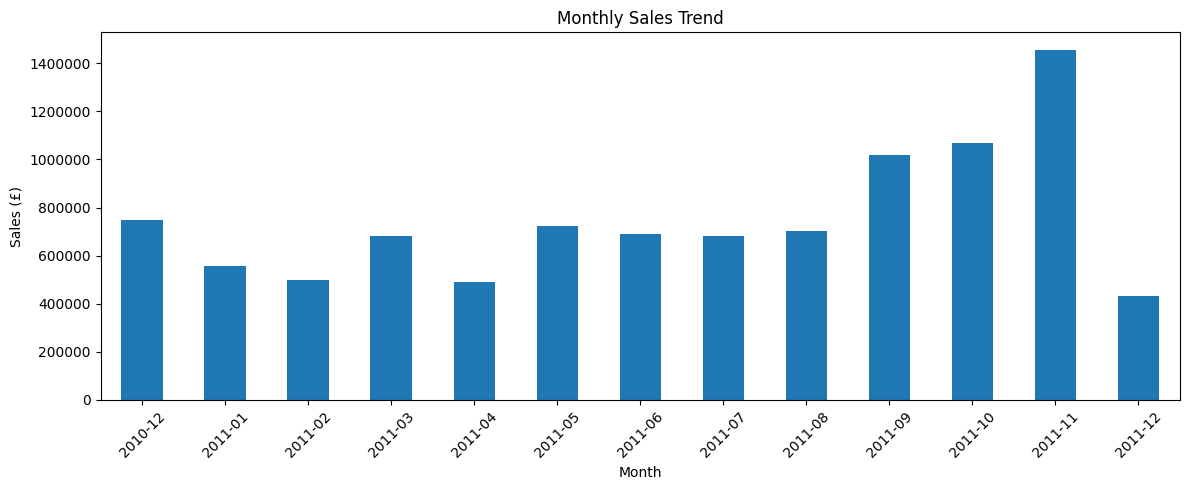

In [ ]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind='bar')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales (£)')
plt.ticklabel_format(axis='y', style='plain')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

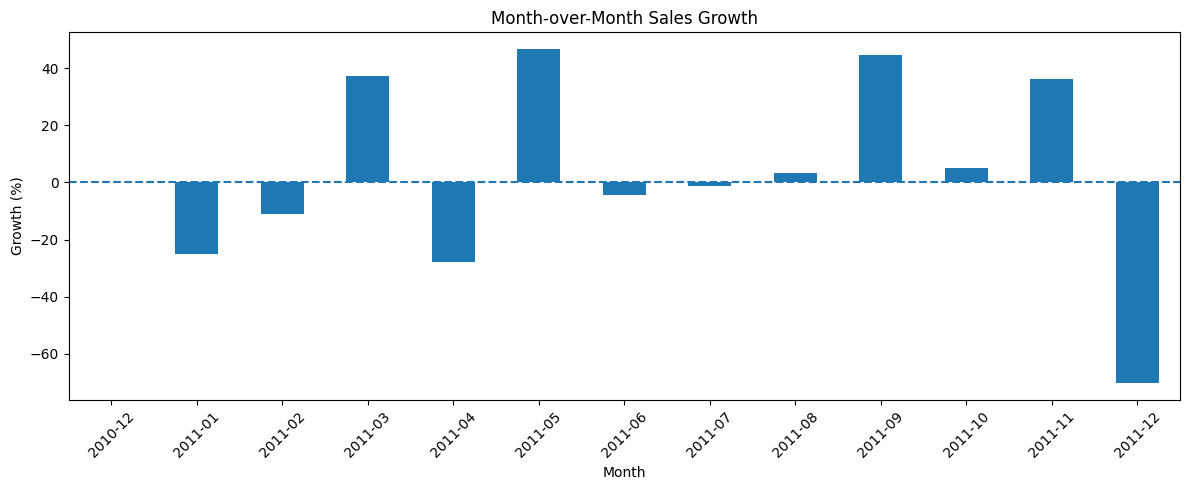

In [ ]:
plt.figure(figsize=(12, 5))

monthly_growth.plot(kind='bar')

plt.title('Month-over-Month Sales Growth')
plt.xlabel('Month')
plt.ylabel('Growth (%)')
plt.axhline(y=0, linestyle='--')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

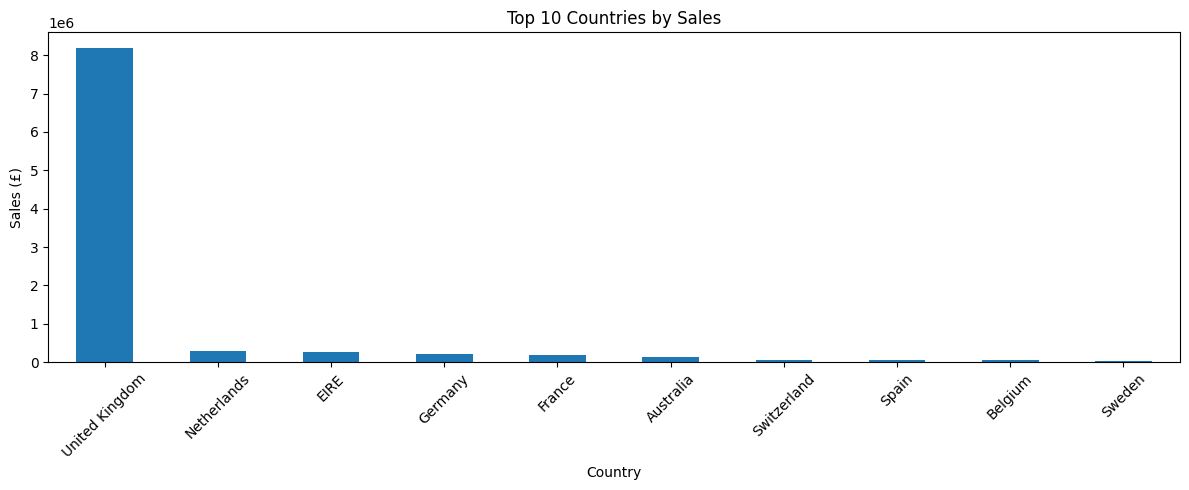

In [ ]:
plt.figure(figsize=(12, 5))

top_10_countries.plot(kind='bar')

plt.title('Top 10 Countries by Sales')
plt.xlabel('Country')
plt.ylabel('Sales (£)')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

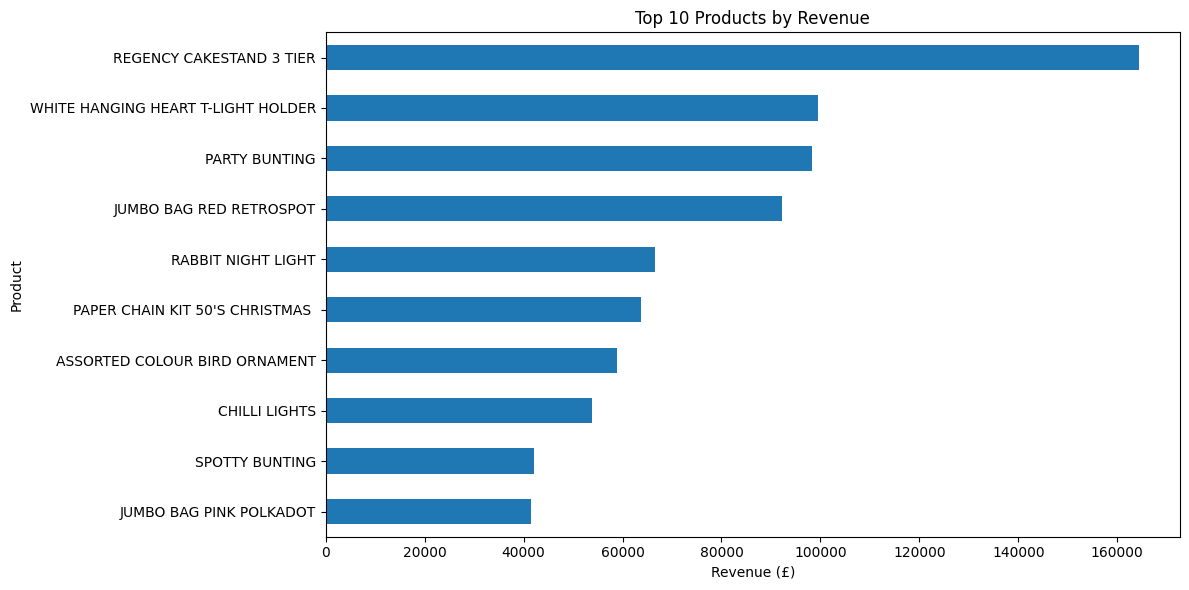

In [ ]:
plt.figure(figsize=(12, 6))

top_10_products.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Product')
plt.tight_layout()

plt.show()

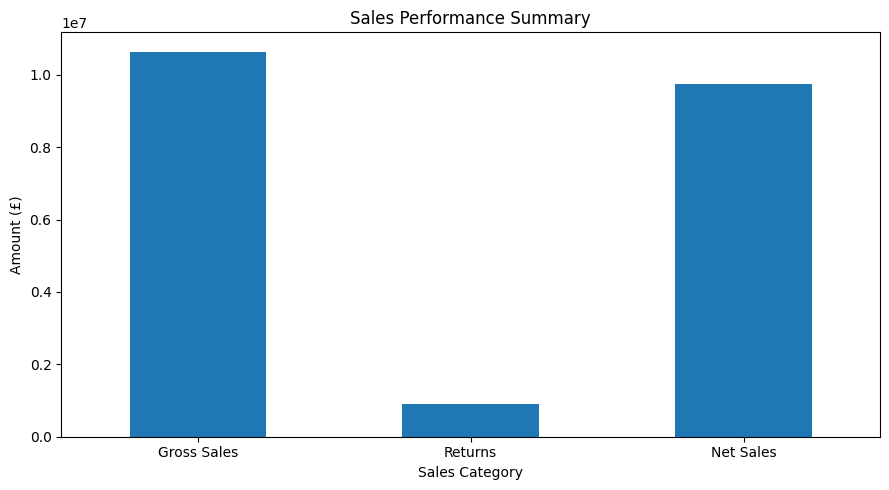

In [ ]:
sales_summary = pd.Series({
    'Gross Sales': gross_sales,
    'Returns': abs(returns),
    'Net Sales': net_sales
})

plt.figure(figsize=(9, 5))

sales_summary.plot(kind='bar')

plt.title('Sales Performance Summary')
plt.xlabel('Sales Category')
plt.ylabel('Amount (£)')
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [ ]:
print("Sales Performance Analysis Completed")
print("Total Charts Created: 5")

Sales Performance Analysis Completed
Total Charts Created: 5


In [ ]:
product_quantity = df[df['Quantity'] > 0].groupby('Description')['Quantity'].sum()

product_quantity = product_quantity.sort_values(ascending=False)

print(product_quantity.head(10))

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48375
WHITE HANGING HEART T-LIGHT HOLDER    37876
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    31555
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


In [ ]:
top_10_quantity = product_quantity.head(10)

print(top_10_quantity)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48375
WHITE HANGING HEART T-LIGHT HOLDER    37876
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    31555
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


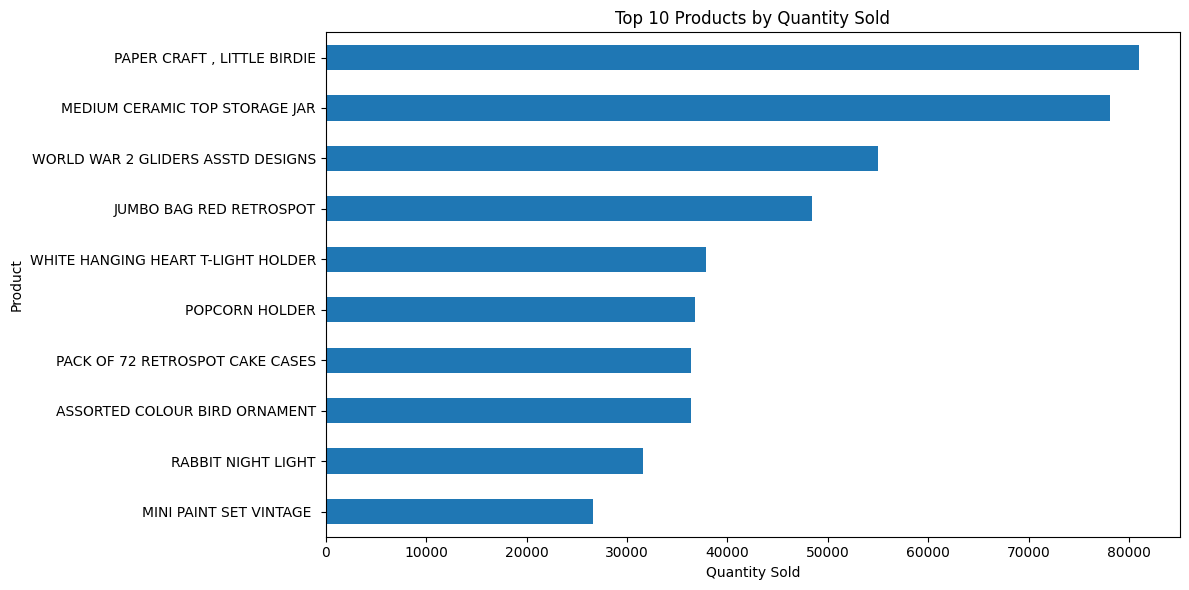

In [ ]:
plt.figure(figsize=(12, 6))

top_10_quantity.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Quantity Sold')
plt.ylabel('Product')
plt.tight_layout()

plt.show()

In [ ]:
product_analysis = pd.concat(
    [product_sales.rename('Revenue'),
     product_quantity.rename('Quantity Sold')],
    axis=1
)

product_analysis = product_analysis.fillna(0)

print(product_analysis.head(10))

                                      Revenue  Quantity Sold
Description                                                 
REGENCY CAKESTAND 3 TIER            164459.49        13862.0
WHITE HANGING HEART T-LIGHT HOLDER   99612.42        37876.0
PARTY BUNTING                        98243.88        18287.0
JUMBO BAG RED RETROSPOT              92175.79        48375.0
RABBIT NIGHT LIGHT                   66661.63        31555.0
PAPER CHAIN KIT 50'S CHRISTMAS       63715.24        19329.0
ASSORTED COLOUR BIRD ORNAMENT        58792.42        36362.0
CHILLI LIGHTS                        53746.66        10419.0
SPOTTY BUNTING                       42030.67         8491.0
JUMBO BAG PINK POLKADOT              41584.43        21448.0


In [ ]:
print("Top 5 Products by Revenue:")
print(product_analysis.sort_values(by='Revenue', ascending=False).head(5))

print("\nTop 5 Products by Quantity Sold:")
print(product_analysis.sort_values(by='Quantity Sold', ascending=False).head(5))

Top 5 Products by Revenue:
                                      Revenue  Quantity Sold
Description                                                 
REGENCY CAKESTAND 3 TIER            164459.49        13862.0
WHITE HANGING HEART T-LIGHT HOLDER   99612.42        37876.0
PARTY BUNTING                        98243.88        18287.0
JUMBO BAG RED RETROSPOT              92175.79        48375.0
RABBIT NIGHT LIGHT                   66661.63        31555.0

Top 5 Products by Quantity Sold:
                                     Revenue  Quantity Sold
Description                                                
PAPER CRAFT , LITTLE BIRDIE             0.00        80995.0
MEDIUM CERAMIC TOP STORAGE JAR       4221.28        78033.0
WORLD WAR 2 GLIDERS ASSTD DESIGNS   13560.09        54951.0
JUMBO BAG RED RETROSPOT             92175.79        48375.0
WHITE HANGING HEART T-LIGHT HOLDER  99612.42        37876.0


## 5. Product Performance Analysis

In this section, product performance is analysed based on revenue and quantity sold. The top-performing products are identified to understand which products contribute most to the business.

In [119]:
product_df = df[
    (df['Quantity'] > 0) &
    ~df['Description'].isin(['DOTCOM POSTAGE', 'POSTAGE', 'Manual'])]

product_sales = product_df.groupby('Description')['Sales'].sum()

product_sales = product_sales.sort_values(ascending=False)

product_analysis = pd.concat(
    [product_sales.rename('Revenue'),
     product_quantity.rename('Quantity Sold')],
    axis=1
)

print(product_analysis.sort_values(by='Revenue', ascending=False).head(10))

                                      Revenue  Quantity Sold
Description                                                 
REGENCY CAKESTAND 3 TIER            174156.54          13862
PAPER CRAFT , LITTLE BIRDIE         168469.60          80995
WHITE HANGING HEART T-LIGHT HOLDER  106236.72          37876
PARTY BUNTING                        99445.23          18287
JUMBO BAG RED RETROSPOT              94159.81          48375
MEDIUM CERAMIC TOP STORAGE JAR       81700.92          78033
RABBIT NIGHT LIGHT                   66870.03          31555
PAPER CHAIN KIT 50'S CHRISTMAS       64875.59          19329
ASSORTED COLOUR BIRD ORNAMENT        58927.62          36362
CHILLI LIGHTS                        54096.36          10419


In [101]:
top_10_products = product_sales.head(10)

print(top_10_products)

Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
Name: Sales, dtype: float64


In [102]:
df[df['Description'] == 'Manual'][[
    'InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice', 'Sales'
]].head(10)

,InvoiceNo,StockCode,Quantity,UnitPrice,Sales
2239,536569,M,1,1.25,1.25
2250,536569,M,1,18.95,18.95
5684,536865,M,1,2.55,2.55
6798,536981,M,2,0.85,1.70
7976,537077,M,12,0.42,5.04
8530,537137,M,36,0.85,30.60
8587,537140,M,1,0.42,0.42
8588,537140,M,1,0.85,0.85
9326,537199,M,1,0.65,0.65
9575,537208,M,4,0.85,3.40


In [103]:
product_df = df[
    (df['Quantity'] > 0) &
    (~df['Description'].isin(['DOTCOM POSTAGE', 'POSTAGE', 'Manual']))
]

product_sales = product_df.groupby('Description')['Sales'].sum()

product_sales = product_sales.sort_values(ascending=False)

top_10_products = product_sales.head(10)

print(top_10_products)

Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: Sales, dtype: float64


In [104]:
product_analysis = pd.concat(
    [product_sales.rename('Revenue'),
     product_quantity.rename('Quantity Sold')],
    axis=1
)

product_analysis = product_analysis.fillna(0)

print(product_analysis.head(10))

                                      Revenue  Quantity Sold
Description                                                 
REGENCY CAKESTAND 3 TIER            174156.54          13862
PAPER CRAFT , LITTLE BIRDIE         168469.60          80995
WHITE HANGING HEART T-LIGHT HOLDER  106236.72          37876
PARTY BUNTING                        99445.23          18287
JUMBO BAG RED RETROSPOT              94159.81          48375
MEDIUM CERAMIC TOP STORAGE JAR       81700.92          78033
RABBIT NIGHT LIGHT                   66870.03          31555
PAPER CHAIN KIT 50'S CHRISTMAS       64875.59          19329
ASSORTED COLOUR BIRD ORNAMENT        58927.62          36362
CHILLI LIGHTS                        54096.36          10419


In [105]:
product_quantity = product_df.groupby('Description')['Quantity'].sum()

product_quantity = product_quantity.sort_values(ascending=False)

product_analysis = pd.concat(
    [product_sales.rename('Revenue'),
     product_quantity.rename('Quantity Sold')],
    axis=1
)

product_analysis = product_analysis.fillna(0)

print(product_analysis.head(10))

                                      Revenue  Quantity Sold
Description                                                 
REGENCY CAKESTAND 3 TIER            174156.54          13862
PAPER CRAFT , LITTLE BIRDIE         168469.60          80995
WHITE HANGING HEART T-LIGHT HOLDER  106236.72          37876
PARTY BUNTING                        99445.23          18287
JUMBO BAG RED RETROSPOT              94159.81          48375
MEDIUM CERAMIC TOP STORAGE JAR       81700.92          78033
RABBIT NIGHT LIGHT                   66870.03          31555
PAPER CHAIN KIT 50'S CHRISTMAS       64875.59          19329
ASSORTED COLOUR BIRD ORNAMENT        58927.62          36362
CHILLI LIGHTS                        54096.36          10419


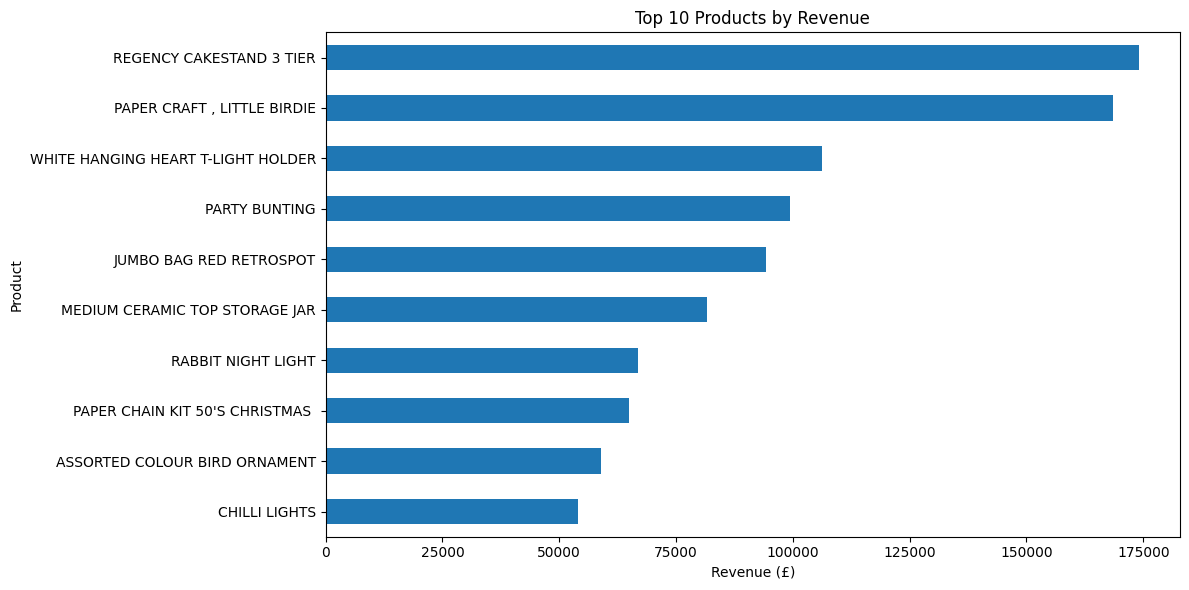

In [106]:
top_10_products = product_analysis.sort_values(
    by='Revenue', ascending=False
).head(10)

plt.figure(figsize=(12, 6))

top_10_products['Revenue'].sort_values().plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Product')

plt.ticklabel_format(axis='x', style='plain')
plt.tight_layout()
plt.show()

In [107]:
customer_orders = customer_df.groupby('CustomerID')['InvoiceNo'].nunique()

print(customer_orders.head(10))

CustomerID
12346     2
12347     7
12348     4
12349     1
12350     1
12352    11
12353     1
12354     1
12355     1
12356     3
Name: InvoiceNo, dtype: int64


In [108]:
order_frequency = customer_orders.value_counts().sort_index()

print(order_frequency.head(15))

InvoiceNo
1     1313
2      817
3      490
4      377
5      288
6      196
7      157
8      117
9       80
10      78
11      62
12      51
13      38
14      41
15      28
Name: count, dtype: int64


## 6. Customer Behaviour Analysis

In this section, customer purchasing behaviour is analysed by examining purchase frequency, repeat customers, one-time customers and customer spending patterns.

In [109]:
repeat_customers = (customer_orders > 1).sum()

one_time_customers = (customer_orders == 1).sum()

total_customers = customer_orders.nunique()  # Don't use this for customer count

print("Repeat Customers:", repeat_customers)
print("One-Time Customers:", one_time_customers)
print("Total Customers:", len(customer_orders))

Repeat Customers: 3059
One-Time Customers: 1313
Total Customers: 4372


In [110]:
customer_revenue = customer_df.groupby('CustomerID')['Sales'].sum()

print(customer_revenue.head(10))

CustomerID
12346       0.00
12347    4310.00
12348    1797.24
12349    1757.55
12350     334.40
12352    1545.41
12353      89.00
12354    1079.40
12355     459.40
12356    2811.43
Name: Sales, dtype: float64


In [112]:
import pandas as pd

analysis_date = customer_df['InvoiceDate'].max() + pd.Timedelta(days=1)

print("Analysis Date:", analysis_date)

Analysis Date: 2011-12-10 12:50:00


## 7. RFM Customer Segmentation

RFM analysis is used to segment customers based on three factors:

- **Recency:** How recently a customer made a purchase.
- **Frequency:** How often a customer made purchases.
- **Monetary:** How much money a customer spent.

Customers are assigned scores based on these factors and grouped into different segments to understand their purchasing behaviour.

In [113]:
rfm = customer_df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (analysis_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'Sales': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

print(rfm.head(10))

            Recency  Frequency  Monetary
CustomerID                              
12346           326          2      0.00
12347             2          7   4310.00
12348            75          4   1797.24
12349            19          1   1757.55
12350           310          1    334.40
12352            36         11   1545.41
12353           204          1     89.00
12354           232          1   1079.40
12355           214          1    459.40
12356            23          3   2811.43


In [114]:
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

print(rfm.head(10))

            Recency  Frequency  Monetary R_Score F_Score M_Score
CustomerID                                                      
12346           326          2      0.00       1       2       1
12347             2          7   4310.00       5       4       5
12348            75          4   1797.24       2       3       4
12349            19          1   1757.55       4       1       4
12350           310          1    334.40       1       1       2
12352            36         11   1545.41       3       5       4
12353           204          1     89.00       1       1       1
12354           232          1   1079.40       1       1       4
12355           214          1    459.40       1       1       2
12356            23          3   2811.43       4       3       5


In [115]:
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

print(rfm.head(10))

            Recency  Frequency  Monetary R_Score F_Score M_Score RFM_Score
CustomerID                                                                
12346           326          2      0.00       1       2       1       121
12347             2          7   4310.00       5       4       5       545
12348            75          4   1797.24       2       3       4       234
12349            19          1   1757.55       4       1       4       414
12350           310          1    334.40       1       1       2       112
12352            36         11   1545.41       3       5       4       354
12353           204          1     89.00       1       1       1       111
12354           232          1   1079.40       1       1       4       114
12355           214          1    459.40       1       1       2       112
12356            23          3   2811.43       4       3       5       435


In [116]:
def segment_customer(row):
    if row['RFM_Score'] == '555':
        return 'Champions'
    elif row['R_Score'] >= 4 and row['F_Score'] >= 3:
        return 'Loyal Customers'
    elif row['R_Score'] >= 4 and row['F_Score'] <= 2:
        return 'Recent Customers'
    elif row['R_Score'] >= 3 and row['F_Score'] >= 2:
        return 'Potential Loyalists'
    elif row['R_Score'] <= 2 and row['F_Score'] >= 3:
        return 'At Risk'
    elif row['R_Score'] <= 2 and row['F_Score'] <= 2:
        return 'Hibernating'
    else:
        return 'Big Spenders'

rfm['Customer_Segment'] = rfm.apply(segment_customer, axis=1)

print(rfm['Customer_Segment'].value_counts())

Customer_Segment
Loyal Customers        1085
Hibernating            1060
Potential Loyalists     706
At Risk                 689
Champions               342
Recent Customers        322
Big Spenders            168
Name: count, dtype: int64


In [117]:
segment_counts = rfm['Customer_Segment'].value_counts()

print(segment_counts)

Customer_Segment
Loyal Customers        1085
Hibernating            1060
Potential Loyalists     706
At Risk                 689
Champions               342
Recent Customers        322
Big Spenders            168
Name: count, dtype: int64


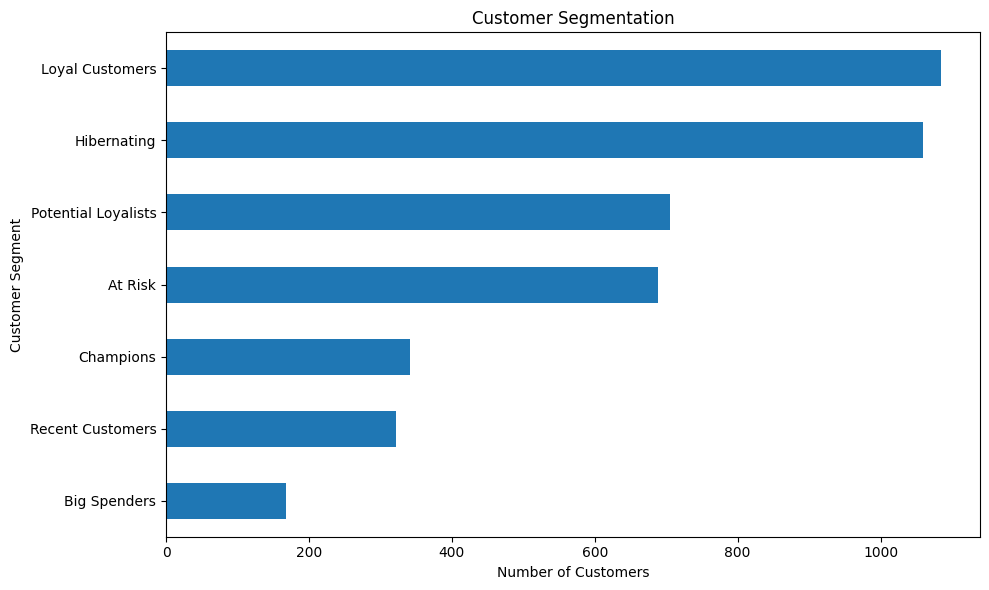

In [118]:
plt.figure(figsize=(10, 6))

segment_counts.sort_values().plot(kind='barh')

plt.title('Customer Segmentation')
plt.xlabel('Number of Customers')
plt.ylabel('Customer Segment')

plt.tight_layout()
plt.show()

#  Business Insights & Recommendations

## Key Business Insights

1. The United Kingdom generated the highest revenue among all countries.
2. November recorded the highest monthly sales.
3. February recorded the lowest monthly sales.
4. Regency Cakestand 3 Tier was the highest-revenue product.
5. Approximately 70% of customers were repeat customers.
6. Hibernating customers formed the largest customer segment in our RFM analysis.

## Business Recommendations

1. Focus marketing strategies on the United Kingdom.
2. Prepare sufficient inventory before the November sales peak.
3. Investigate the reasons behind lower sales in February.
4. Promote high-performing products to increase revenue.
5. Introduce loyalty offers to encourage repeat purchases.
6. Target hibernating customers with personalised offers to encourage them to return.

## Conclusion

The analysis provides insights into sales performance, product performance and customer purchasing behaviour. These findings can help businesses improve marketing strategies, customer retention and overall sales performance.